## 1. Import libraries and load dataset

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PolynomialFeatures
)
from sklearn.impute import SimpleImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv("telco_cleaned_eda.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (7043, 39)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason,Monthly Charges_IQR_Outlier,Total Charges_IQR_Outlier,Tenure Months_IQR_Outlier,Monthly Charges_Capped,Total Charges_Capped,Tenure Months_Domain_Invalid
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer,0,0,0,53.85,108.15,0
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved,0,0,0,70.70,151.65,0
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved,0,0,0,99.65,820.50,0
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved,0,0,0,104.80,3046.05,0
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices,0,0,0,103.70,5036.30,0


## 2. Define regression target

In [7]:
# CLTV proxy

if "Total Revenue" in df.columns:
    target = "Total Revenue"

elif "Total Charges" in df.columns:
    target = "Total Charges"

else:
    raise ValueError("No revenue/charges column found.")

df[target] = pd.to_numeric(
    df[target],
    errors="coerce"
)

df = df.dropna(
    subset=[target]
).copy()

print("Regression target:", target)

display(df[[target]].describe())

Regression target: Total Charges


,Total Charges
count,7032.000000
mean,2283.300441
std,2266.771362
min,18.800000
25%,401.450000
50%,1397.475000
75%,3794.737500
max,8684.800000


## 3. Select regression features


In [8]:
regression_features = [
    "Gender",
    "Senior Citizen",
    "Partner",
    "Dependents",
    "Tenure Months",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Monthly Charges"
]

# Support singular column naming
if "Monthly Charges" not in df.columns and "Monthly Charge" in df.columns:
    regression_features[
        regression_features.index("Monthly Charges")
    ] = "Monthly Charge"

# Prevent target leakage
regression_features = [
    col for col in regression_features
    if col != target
]

missing_features = [
    col for col in regression_features
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing regression features: {missing_features}"
    )

X = df[regression_features].copy()

y = df[target].copy()

print("Target:", target)
print("X shape:", X.shape)
print("Number of input features:", X.shape[1])

display(X.head())

Target: Total Charges
X shape: (7032, 18)
Number of input features: 18


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70


## 4. Identify numerical and categorical columns

In [9]:
num_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numeric columns:")
print(num_cols)

print("\nCategorical columns:")
print(cat_cols)

Numeric columns:
['Tenure Months', 'Monthly Charges']

Categorical columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


## 5. Preprocessing

In [10]:
# Numerical preprocessing

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])


# Baseline preprocessing

baseline_preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, num_cols),
    ("cat", categorical_preprocessor, cat_cols)
])


# Polynomial numerical preprocessing

polynomial_numeric = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("scaler_before", StandardScaler()),

    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),

    ("scaler_after", StandardScaler())
])


# Polynomial preprocessing

polynomial_preprocessor = ColumnTransformer([
    ("num_poly", polynomial_numeric, num_cols),
    ("cat", categorical_preprocessor, cat_cols)
])

## 6. Train-test split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5625
Testing samples: 1407


## 7. Define regression models

In [12]:
models = {

    # Baseline model
    "Linear Regression": Pipeline([
        ("preprocessor", baseline_preprocessor),
        ("model", LinearRegression())
    ]),

    # Polynomial Regression
    "Polynomial Regression": Pipeline([
        ("preprocessor", polynomial_preprocessor),
        ("model", LinearRegression())
    ]),

    # Ridge Regularization
    "Ridge Regression": Pipeline([
        ("preprocessor", polynomial_preprocessor),
        ("model", Ridge(alpha=1.0))
    ]),

    # Lasso Regularization
    "Lasso Regression": Pipeline([
        ("preprocessor", polynomial_preprocessor),
        ("model", Lasso(
            alpha=0.01,
            max_iter=20000
        ))
    ]),

    # Random Forest
    "Random Forest": Pipeline([
        ("preprocessor", baseline_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    # Gradient Boosting
    "Gradient Boosting": Pipeline([
        ("preprocessor", baseline_preprocessor),
        ("model", GradientBoostingRegressor(
            random_state=42
        ))
    ])
}

## 8. Train and evaluate models

In [13]:
results = []

fitted_models = {}

test_predictions = {}

for name, pipe in models.items():

    print("\n" + "=" * 50)
    print("Training:", name)
    print("=" * 50)

    pipe.fit(
        X_train,
        y_train
    )

    # Training predictions
    train_pred = pipe.predict(X_train)

    # Testing predictions
    test_pred = pipe.predict(X_test)

    # Evaluation
    train_mae = mean_absolute_error(
        y_train,
        train_pred
    )

    test_mae = mean_absolute_error(
        y_test,
        test_pred
    )

    train_rmse = np.sqrt(
        mean_squared_error(
            y_train,
            train_pred
        )
    )

    test_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            test_pred
        )
    )

    train_r2 = r2_score(
        y_train,
        train_pred
    )

    test_r2 = r2_score(
        y_test,
        test_pred
    )

    results.append({

        "Model": name,

        "Train MAE": train_mae,
        "Test MAE": test_mae,

        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,

        "Train R2": train_r2,
        "Test R2": test_r2

    })

    fitted_models[name] = pipe

    test_predictions[name] = test_pred

    print("Test MAE:", round(test_mae, 4))
    print("Test RMSE:", round(test_rmse, 4))
    print("Test R2:", round(test_r2, 4))


Training: Linear Regression
Test MAE: 546.1317
Test RMSE: 676.781
Test R2: 0.9123

Training: Polynomial Regression
Test MAE: 46.7293
Test RMSE: 70.2298
Test R2: 0.9991

Training: Ridge Regression
Test MAE: 46.7265
Test RMSE: 70.2888
Test R2: 0.9991

Training: Lasso Regression
Test MAE: 46.7089
Test RMSE: 70.2213
Test R2: 0.9991

Training: Random Forest
Test MAE: 55.4448
Test RMSE: 83.3509
Test R2: 0.9987

Training: Gradient Boosting
Test MAE: 69.326
Test RMSE: 97.9301
Test R2: 0.9982


## 9. Model comparison table

In [14]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Test RMSE"
).reset_index(drop=True)

print("MODEL COMPARISON")

display(results_df.round(4))

MODEL COMPARISON


,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Lasso Regression,44.9056,46.7089,66.3877,70.2213,0.9991,0.9991
1,Polynomial Regression,44.9122,46.7293,66.3873,70.2298,0.9991,0.9991
2,Ridge Regression,45.1011,46.7265,66.5050,70.2888,0.9991,0.9991
3,Random Forest,19.7363,55.4448,29.4174,83.3509,0.9998,0.9987
4,Gradient Boosting,62.9190,69.3260,88.8428,97.9301,0.9985,0.9982
5,Linear Regression,559.3521,546.1317,692.9567,676.7810,0.9061,0.9123


## Compare baseline vs polynomial vs regularized models

In [15]:
focused_models = [
    "Linear Regression",
    "Polynomial Regression",
    "Ridge Regression",
    "Lasso Regression"
]

comparison_df = results_df[
    results_df["Model"].isin(focused_models)
].set_index("Model").loc[focused_models].reset_index()

display(comparison_df.round(4))

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,559.3521,546.1317,692.9567,676.7810,0.9061,0.9123
1,Polynomial Regression,44.9122,46.7293,66.3873,70.2298,0.9991,0.9991
2,Ridge Regression,45.1011,46.7265,66.5050,70.2888,0.9991,0.9991
3,Lasso Regression,44.9056,46.7089,66.3877,70.2213,0.9991,0.9991


## Visual comparison

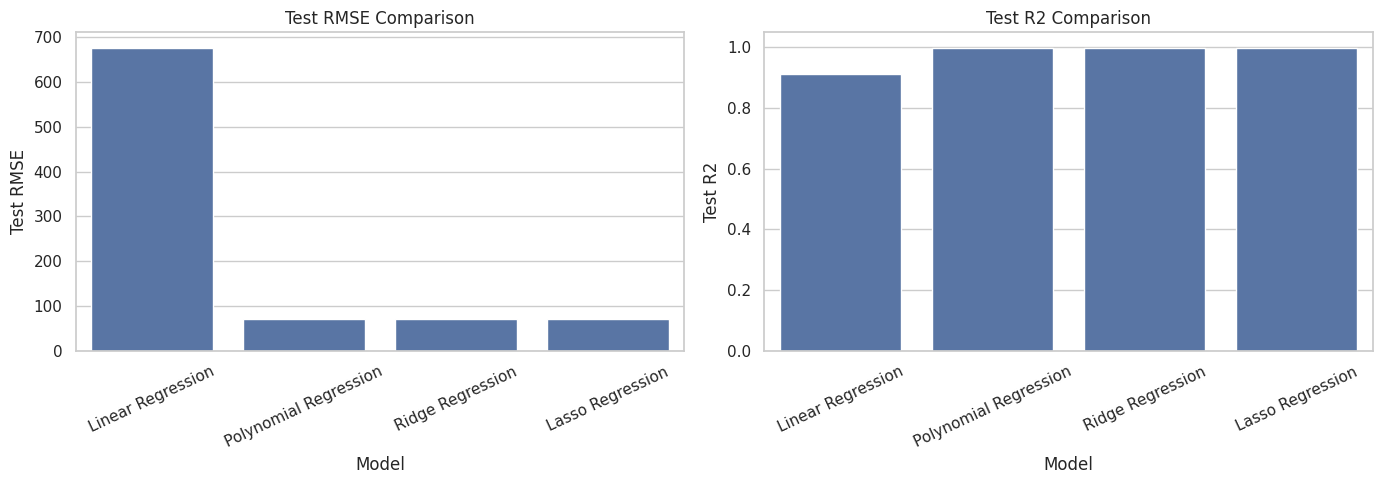

In [16]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Test RMSE",
    ax=axes[0]
)

axes[0].set_title(
    "Test RMSE Comparison"
)

axes[0].tick_params(
    axis="x",
    rotation=25
)


sns.barplot(
    data=comparison_df,
    x="Model",
    y="Test R2",
    ax=axes[1]
)

axes[1].set_title(
    "Test R2 Comparison"
)

axes[1].tick_params(
    axis="x",
    rotation=25
)

plt.tight_layout()
plt.show()

## 10. Compare regression coefficients
هنا هنشوف تأثير الـ Ridge والـ Lasso على الـ coefficients.
- Ridge: يقلل حجم الـ coefficients.
- Lasso: ممكن يخلي بعض الـ coefficients تساوي صفر.
- Polynomial: بيضيف coefficients جديدة خاصة بالـ squared terms والـ interactions.

In [17]:
def extract_coefficients(model_pipeline, model_name):

    preprocessor = model_pipeline.named_steps[
        "preprocessor"
    ]

    model = model_pipeline.named_steps[
        "model"
    ]

    feature_names = preprocessor.get_feature_names_out()

    coefficients = model.coef_

    coef_df = pd.DataFrame({

        "Model": model_name,

        "Feature": feature_names,

        "Coefficient": coefficients,

        "Absolute Coefficient": np.abs(coefficients)

    })

    return coef_df


coefficient_results = []

linear_models = [
    "Linear Regression",
    "Polynomial Regression",
    "Ridge Regression",
    "Lasso Regression"
]

for name in linear_models:

    coef_df = extract_coefficients(
        fitted_models[name],
        name
    )

    coefficient_results.append(coef_df)


coefficients_df = pd.concat(
    coefficient_results,
    ignore_index=True
)

## Display the most important coefficients

In [18]:
for name in linear_models:

    print("\n", name)

    display(

        coefficients_df[
            coefficients_df["Model"] == name
        ]

        .nlargest(
            15,
            "Absolute Coefficient"
        )

        [["Feature", "Coefficient"]]

    )


 Linear Regression


,Feature,Coefficient
0,num__Tenure Months,1497.616999
1,num__Monthly Charges,1263.292235
44,cat__Payment Method_Mailed check,171.167561
38,cat__Contract_Two year,-139.470772
21,cat__Online Backup_No,-133.564890
43,cat__Payment Method_Electronic check,-109.883875
18,cat__Online Security_No,-102.940471
16,cat__Internet Service_Fiber optic,-102.635146
27,cat__Tech Support_No,-102.481551
23,cat__Online Backup_Yes,100.481380



 Polynomial Regression


,Feature,Coefficient
45,num_poly__Tenure Months,1585.926929
46,num_poly__Monthly Charges,976.196957
48,num_poly__Tenure Months Monthly Charges,740.888347
89,cat__Payment Method_Bank transfer (automatic),-3.978969
64,cat__Internet Service_Fiber optic,-3.355432
80,cat__Streaming TV_Yes,-2.403866
91,cat__Payment Method_Electronic check,2.295326
57,cat__Dependents_Yes,-2.290900
56,cat__Dependents_No,2.290900
63,cat__Internet Service_DSL,2.287667



 Ridge Regression


,Feature,Coefficient
93,num_poly__Tenure Months,1585.063048
94,num_poly__Monthly Charges,860.771249
96,num_poly__Tenure Months Monthly Charges,740.503849
112,cat__Internet Service_Fiber optic,54.751850
111,cat__Internet Service_DSL,-34.666529
131,cat__Streaming Movies_Yes,29.426194
128,cat__Streaming TV_Yes,27.189096
107,cat__Phone Service_Yes,23.609909
106,cat__Phone Service_No,-23.609909
109,cat__Multiple Lines_No phone service,-23.609909



 Lasso Regression


,Feature,Coefficient
141,num_poly__Tenure Months,1585.858858
142,num_poly__Monthly Charges,970.303152
144,num_poly__Tenure Months Monthly Charges,740.884243
185,cat__Payment Method_Bank transfer (automatic),-4.720948
152,cat__Dependents_No,4.484377
150,cat__Partner_No,-2.929186
182,cat__Contract_Two year,-2.586652
177,cat__Streaming Movies_No,-2.515598
170,cat__Device Protection_Yes,1.926844
148,cat__Senior Citizen_No,1.740578


## Compare coefficient magnitudes

In [19]:
coefficient_summary = (

    coefficients_df

    .groupby("Model")

    .agg(

        Number_of_Coefficients=(
            "Coefficient",
            "count"
        ),

        Mean_Absolute_Coefficient=(
            "Absolute Coefficient",
            "mean"
        ),

        Maximum_Absolute_Coefficient=(
            "Absolute Coefficient",
            "max"
        ),

        Zero_Coefficients=(
            "Coefficient",
            lambda x: np.isclose(x, 0).sum()
        )

    )

    .reset_index()

)

display(coefficient_summary.round(4))

,Model,Number_of_Coefficients,Mean_Absolute_Coefficient,Maximum_Absolute_Coefficient,Zero_Coefficients
0,Lasso Regression,48,69.4374,1585.8589,22
1,Linear Regression,45,109.4197,1497.6170,0
2,Polynomial Regression,48,70.0111,1585.9269,0
3,Ridge Regression,48,76.9040,1585.0630,0


## 11. Written interpretation

In [20]:
best_focused = comparison_df.loc[
    comparison_df["Test RMSE"].idxmin()
]

baseline = comparison_df[
    comparison_df["Model"] == "Linear Regression"
].iloc[0]

print("MODEL INTERPRETATION")
print("-" * 50)

print(
    "Best model among the four:",
    best_focused["Model"]
)

print(
    "Test RMSE:",
    round(best_focused["Test RMSE"], 4)
)

print(
    "Test R2:",
    round(best_focused["Test R2"], 4)
)


if best_focused["Model"] == "Linear Regression":

    print(
        "\nThe baseline Linear Regression achieved "
        "the best test RMSE among the four models."
    )

    print(
        "Polynomial expansion and regularization "
        "did not improve prediction performance "
        "on this test split."
    )

else:

    improvement = (

        (baseline["Test RMSE"] -
         best_focused["Test RMSE"])

        / baseline["Test RMSE"]

    ) * 100

    print(
        f"\nThe selected model improved test RMSE "
        f"by {improvement:.2f}% compared with "
        f"baseline Linear Regression."
    )


lasso_zeros = coefficient_summary.loc[
    coefficient_summary["Model"] == "Lasso Regression",
    "Zero_Coefficients"
].iloc[0]

print(
    "\nNumber of zero coefficients in Lasso:",
    int(lasso_zeros)
)

print(
    "\nInterpretation:"
)

print(
    "Polynomial Regression captures nonlinear "
    "relationships by introducing squared and "
    "interaction terms."
)

print(
    "Ridge reduces coefficient magnitudes and "
    "helps control overfitting."
)

print(
    "Lasso performs feature selection by shrinking "
    "some coefficients to zero."
)

print(
    "The final model should be selected based on "
    "test performance and the train-test gap."
)

MODEL INTERPRETATION
--------------------------------------------------
Best model among the four: Lasso Regression
Test RMSE: 70.2213
Test R2: 0.9991

The selected model improved test RMSE by 89.62% compared with baseline Linear Regression.

Number of zero coefficients in Lasso: 22

Interpretation:
Polynomial Regression captures nonlinear relationships by introducing squared and interaction terms.
Ridge reduces coefficient magnitudes and helps control overfitting.
Lasso performs feature selection by shrinking some coefficients to zero.
The final model should be selected based on test performance and the train-test gap.


## 12. Select and save the best model

In [24]:
best_name = results_df.iloc[0]["Model"]

best_model = fitted_models[best_name]

print("Best model:", best_name)

best_predictions = best_model.predict(
    X_test
)

model_path = "cltv_model.pkl"

joblib.dump(
    best_model,
    model_path,
    compress=3
)

print("\nModel saved successfully!")

print(
    "File size:",
    os.path.getsize(model_path),
    "bytes"
)

Best model: Lasso Regression

Model saved successfully!
File size: 2846 bytes


## 13. Verify saved model

In [25]:
loaded_model = joblib.load(
    model_path
)

print("CLTV model loaded successfully!")

print(
    "Model type:",
    type(loaded_model)
)

saved_preprocessor = loaded_model.named_steps[
    "preprocessor"
]

print(
    "Number of original input features:",
    len(saved_preprocessor.feature_names_in_)
)

print("\nOriginal input features:")

for i, feature in enumerate(
    saved_preprocessor.feature_names_in_,
    start=1
):

    print(i, feature)


# Test prediction

sample_prediction = loaded_model.predict(
    X_test.head(5)
)

display(
    pd.DataFrame({

        "Actual": y_test.head(5).values,

        "Predicted": sample_prediction

    })
)

print("\nCLTV model training and verification completed!")

CLTV model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>
Number of original input features: 18

Original input features:
1 Gender
2 Senior Citizen
3 Partner
4 Dependents
5 Tenure Months
6 Phone Service
7 Multiple Lines
8 Internet Service
9 Online Security
10 Online Backup
11 Device Protection
12 Tech Support
13 Streaming TV
14 Streaming Movies
15 Contract
16 Paperless Billing
17 Payment Method
18 Monthly Charges


,Actual,Predicted
0,1108.20,1063.308197
1,1931.30,1906.251462
2,2383.60,2412.737574
3,1218.65,1274.474381
4,2080.10,2058.234304



CLTV model training and verification completed!
